# Prüfungsleistung Künstliche Intelligeng - Teil II / Reichardt

Erstellen Sie einen Klassifikator für Emotionen aus kurzen Videoclips, die bereits durch ein gegebenes Vorverarbeitungssystem gelaufen sind und verschiedene Features bestimmt haben.

1. Schritt : Daten einlesen (eine Sequenz mit einer einzelnen Emotion)
2. Schritt : Erzeugen der Basismaße aus den gemessenen Daten
3. Schritt : Akkumulation mit Dempsters Regel
4. Schritt : Entscheidung / Klassifikation

Zudem soll Ihr Klassifikator getestet werden, die Schritte begründet werden und die Ergebnisse interpretiert werden.

Nachfolgend ist ein Raster dafür mit Dummy Werten vorbereitet.

# Einlesen einer Aufnahme
Die Aufnahme ist eine CSV-Logdatei des Gesichtssystems. Alle Daten werden in
`aufnahme` als Liste von Dictionaries bereitgestellt. `merkmale` enthält die
numerischen Spalten als NumPy-Arrays; fehlende Werte sind `np.nan`.

Mit `LOGDATEI` kann eine Aufnahme ausgewählt werden. Bei `None` wird die zuletzt
geänderte Datei `logs/klassifikatoren_*.csv` im aktuellen Arbeitsverzeichnis geladen.

Benötigt werden NumPy und Matplotlib; die CSV-Datei wird mit der Python-
Standardbibliothek gelesen. Die Kamera und MediaPipe werden hier nicht benötigt.


In [1]:
from pathlib import Path
import csv
import math
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

# Nur bei fehlenden Paketen einmalig aktivieren, danach ggf. Kernel neu starten:
# %pip install numpy matplotlib

LOGDATEI = None  # z. B. Path("logs/klassifikatoren_20261115_170000.csv")
LOGORDNER = Path("logs")

if LOGDATEI is None:
    dateien = list(LOGORDNER.glob("klassifikatoren_*.csv"))
    if not dateien:
        raise FileNotFoundError(
            f"Keine Logdatei in {LOGORDNER.resolve()}. LOGDATEI oder LOGORDNER anpassen."
        )
    logdatei = max(dateien, key=lambda p: (p.stat().st_mtime_ns, p.name))
else:
    logdatei = Path(LOGDATEI).expanduser()

with logdatei.open(encoding="utf-8-sig", newline="") as datei:
    reader = csv.DictReader(datei, delimiter=";")
    spalten = reader.fieldnames or []
    aufnahme = list(reader)

if not aufnahme:
    raise ValueError("Die ausgewählte Logdatei enthält keine Messzeilen.")
if "laufzeit_s" not in spalten:
    raise ValueError("Spalte laufzeit_s fehlt. Erwartet wird ein CSV-Log mit Semikolon-Trennung.")

merkmale = {}
for spalte in spalten:
    if spalte == "zeitstempel":
        continue
    werte = []
    numerisch = True
    for zeile in aufnahme:
        text = zeile.get(spalte)
        if text is None or not text.strip():
            werte.append(np.nan)
        else:
            try:
                werte.append(float(text))
            except ValueError:
                numerisch = False
                break
    if numerisch:
        merkmale[spalte] = np.asarray(werte, dtype=float)

if "laufzeit_s" not in merkmale or not np.isfinite(merkmale["laufzeit_s"]).any():
    raise ValueError("Die Aufnahme enthält keine gültige numerische Zeitachse.")

print("Aufnahme:", logdatei.resolve())
print("Messzeilen:", len(aufnahme))
print("Numerische Spalten:", ", ".join(merkmale))
print("Vorschau der ersten drei Messzeilen:")
display(aufnahme[:3])

# Beispiele für den späteren Zugriff:
# merkmale["auge_links_oeffnung"]
# merkmale["mund_oeffnung_geglaettet"]


Aufnahme: /Users/dirkreichardt/Downloads/test/logs/klassifikatoren_20261115_212928_163209.csv
Messzeilen: 49
Numerische Spalten: laufzeit_s, frame, gesicht_erkannt, kanten_kreis_alter_s, auge_links_oeffnung, auge_rechts_oeffnung, auge_links_roh, auge_rechts_roh, auge_links_lidverhaeltnis, auge_rechts_lidverhaeltnis, auge_links_kalibriert, auge_rechts_kalibriert, stirn_horizontal, nasenwurzel_horizontal, nasenwurzel_vertikal, wange_links_vertikal, wange_rechts_vertikal, kopfneigung_wert, kopfneigung_grad, mund_oeffnung_roh, mund_oeffnung_geglaettet, brille_indiz, brille_erkannt
Vorschau der ersten drei Messzeilen:


[{'zeitstempel': '2026-11-15T21:29:28.293+01:00',
  'laufzeit_s': '0.130305',
  'frame': '1',
  'gesicht_erkannt': '0',
  'kanten_kreis_alter_s': '',
  'auge_links_oeffnung': '',
  'auge_rechts_oeffnung': '',
  'auge_links_roh': '',
  'auge_rechts_roh': '',
  'auge_links_lidverhaeltnis': '',
  'auge_rechts_lidverhaeltnis': '',
  'auge_links_kalibriert': '',
  'auge_rechts_kalibriert': '',
  'stirn_horizontal': '',
  'nasenwurzel_horizontal': '',
  'nasenwurzel_vertikal': '',
  'wange_links_vertikal': '',
  'wange_rechts_vertikal': '',
  'kopfneigung_wert': '',
  'kopfneigung_grad': '',
  'mund_oeffnung_roh': '',
  'mund_oeffnung_geglaettet': '',
  'brille_indiz': '',
  'brille_erkannt': ''},
 {'zeitstempel': '2026-11-15T21:29:28.447+01:00',
  'laufzeit_s': '0.284371',
  'frame': '2',
  'gesicht_erkannt': '0',
  'kanten_kreis_alter_s': '',
  'auge_links_oeffnung': '',
  'auge_rechts_oeffnung': '',
  'auge_links_roh': '',
  'auge_rechts_roh': '',
  'auge_links_lidverhaeltnis': '',
  'aug

# Basismaße erzeugen
Die Alternativenmenge ist
$\Omega=\{\mathrm{anger},\mathrm{joy},\mathrm{fear},\mathrm{surprise},\mathrm{disgust},\mathrm{sadness}\}$.
Für dieses Lehrbeispiel wird angenommen, dass genau eine dieser Klassen zutrifft.

Jedes Dummy-Basismaß weist einer Menge aus **2–4 Emotionen** eine Masse zwischen
**0,5 und 0,7** zu. Die Restmasse liegt auf $\Omega$ und steht für Unwissenheit.
Es gilt $m(\varnothing)=0$ und $\sum_{A\subseteq\Omega}m(A)=1$.

**Die Dummies verwenden die eingelesenen Messwerte noch nicht.** Später werden sie
hier durch die Abbildung der Gesichtsmerkmale über Fuzzy-Mengen ersetzt.
Fuzzy-Zugehörigkeitsgrade sind nicht automatisch Basismaße: Die Zuordnung muss
Massen für Emotionsmengen und eine gültige Restmasse auf $\Omega$ liefern.


In [3]:
KLASSEN = ("anger", "joy", "fear", "surprise", "disgust", "sadness")
Omega = frozenset(KLASSEN)

# frozenset ist eine unveränderliche Menge und kann als Dictionary-Schlüssel dienen.
# Pro Dummy: eine fokale Teilmenge mit 2–4 Emotionen plus Restmasse auf Omega.
m1 = {
    frozenset({"joy", "surprise"}): 0.60,
    Omega: 0.40,
}
m2 = {
    frozenset({"fear", "surprise", "disgust"}): 0.70,
    Omega: 0.30,
}
m3 = {
    frozenset({"anger", "joy", "fear", "sadness"}): 0.50,
    Omega: 0.50,
}


def pruefe_basismass(m):
    """Gültigkeit eines normalisierten Basismaßes über Omega prüfen."""
    if not m:
        raise ValueError("Ein Basismaß darf nicht leer sein.")
    for menge, wert in m.items():
        if not isinstance(menge, frozenset) or not menge.issubset(Omega):
            raise ValueError(f"Ungültige Emotionsmenge: {menge}")
        if not math.isfinite(wert) or not 0 <= wert <= 1:
            raise ValueError(f"Ungültige Masse: {wert}")
        if not menge and wert != 0:
            raise ValueError("Die leere Menge muss Masse 0 haben.")
    if not math.isclose(sum(m.values()), 1.0, abs_tol=1e-9):
        raise ValueError("Die Massen müssen in Summe 1 ergeben.")


def mengenname(menge):
    if menge == Omega:
        return "Omega (Unwissenheit)"
    return "{" + ", ".join(e for e in KLASSEN if e in menge) + "}"


for name, m in [("m1", m1), ("m2", m2), ("m3", m3)]:
    pruefe_basismass(m)
    print(name)
    for menge, wert in m.items():
        print(f"  m({mengenname(menge)}) = {wert:.2f}")

# TODO: Dummies durch Basismaße aus merkmale/aufnahme und Fuzzy-Regeln ersetzen.


m1
  m({joy, surprise}) = 0.60
  m(Omega (Unwissenheit)) = 0.40
m2
  m({fear, surprise, disgust}) = 0.70
  m(Omega (Unwissenheit)) = 0.30
m3
  m({anger, joy, fear, sadness}) = 0.50
  m(Omega (Unwissenheit)) = 0.50


# Klassifikation
Die Basismaße werden schrittweise kombiniert:
$ m = (m_1 \oplus m_2) \oplus m_3 $.
Dempsters normalisierte Regel lautet für $A\ne\varnothing$:

$$
(m_a\oplus m_b)(A)
=\frac{\sum_{B\cap C=A}m_a(B)m_b(C)}{1-K},
\qquad K=\sum_{B\cap C=\varnothing}m_a(B)m_b(C).
$$

Bei vollständigem Konflikt ($K=1$) ist diese Regel nicht definiert.
Für eine Emotion $e$ werden anschließend berechnet:

$$
\operatorname{Bel}(\{e\})=\sum_{A\subseteq\{e\}}m(A),
\qquad
\operatorname{Pl}(\{e\})=\sum_{A\cap\{e\}\ne\varnothing}m(A).
$$

Belief beschreibt die eindeutig dieser Emotion zugewiesene Unterstützung,
Plausibilität die noch mit ihr vereinbare Unterstützung. Die Balken müssen
über die Emotionen **nicht** auf 1 summieren.

Die Kombination setzt passend modellierte, unterscheidbare Evidenzquellen voraus.
Überlappende Gesichtsmerkmale dürfen später nicht unkritisch als unabhängige
Belege mehrfach gezählt werden. Die folgende Ausgabe ist eine Demonstration
mit Dummy-Massen und noch keine aus der Aufnahme abgeleitete Emotionserkennung.

Formale Referenz: [Shafer & Logan, Implementing Dempster's Rule for Hierarchical Evidence](https://glennshafer.com/assets/downloads/articles/article29_dempster.pdf).


Konflikt bei m1 ⊕ m2:       K = 0.0000
Konflikt bei (m1 ⊕ m2) ⊕ m3: K = 0.2100

Kombiniertes Basismaß:
  m({surprise}) = 0.2658
  m({fear}) = 0.1772
  m({fear, surprise, disgust}) = 0.1772
  m({joy}) = 0.1139
  m({joy, surprise}) = 0.1139
  m({anger, joy, fear, sadness}) = 0.0759
  m(Omega (Unwissenheit)) = 0.0759

Emotion          Belief   Plausibilität
anger            0.000       0.152
joy              0.114       0.380
fear             0.177       0.506
surprise         0.266       0.633
disgust          0.000       0.253
sadness          0.000       0.152


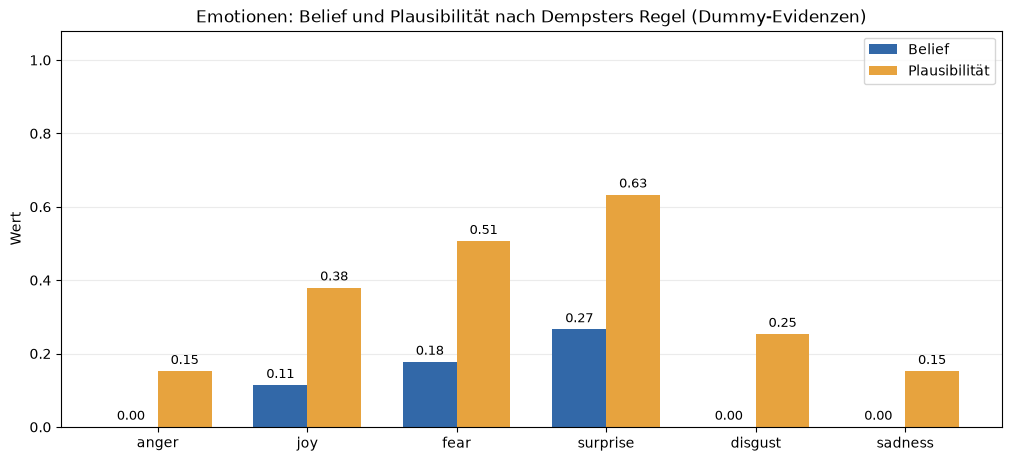

In [4]:
def dempster(ma, mb):
    """Zwei Basismaße kombinieren; Rückgabe: kombiniertes Maß und Konflikt K."""
    pruefe_basismass(ma)
    pruefe_basismass(mb)
    unnormiert = {}
    konflikt = 0.0
    for A, masse_a in ma.items():
        for B, masse_b in mb.items():
            schnitt = A & B
            produkt = masse_a * masse_b
            if not schnitt:
                konflikt += produkt
            else:
                unnormiert[schnitt] = unnormiert.get(schnitt, 0.0) + produkt
    if 1.0 - konflikt <= 1e-12:
        raise ValueError(f"Vollständiger bzw. numerisch fast vollständiger Konflikt: K={konflikt:.6f}")
    kombiniert = {A: wert / (1.0 - konflikt) for A, wert in unnormiert.items()
                  if wert > 0}
    pruefe_basismass(kombiniert)
    return kombiniert, konflikt


def belief(m, hypothese):
    return sum(wert for A, wert in m.items() if A.issubset(hypothese))


def plausibilitaet(m, hypothese):
    return sum(wert for A, wert in m.items() if A & hypothese)


m12, K12 = dempster(m1, m2)
m_gesamt, K123 = dempster(m12, m3)
print(f"Konflikt bei m1 ⊕ m2:       K = {K12:.4f}")
print(f"Konflikt bei (m1 ⊕ m2) ⊕ m3: K = {K123:.4f}")
print("\nKombiniertes Basismaß:")
for menge, wert in sorted(m_gesamt.items(), key=lambda item: (-item[1], len(item[0]))):
    print(f"  m({mengenname(menge)}) = {wert:.4f}")

bel_werte = np.array([belief(m_gesamt, frozenset({e})) for e in KLASSEN])
pl_werte = np.array([plausibilitaet(m_gesamt, frozenset({e})) for e in KLASSEN])

print("\nEmotion          Belief   Plausibilität")
for emotion, bel, pl in zip(KLASSEN, bel_werte, pl_werte):
    print(f"{emotion:12s}    {bel:6.3f}      {pl:6.3f}")

x = np.arange(len(KLASSEN))
breite = 0.36
fig, ax = plt.subplots(figsize=(10, 4.5), layout="constrained")
bel_balken = ax.bar(x - breite/2, bel_werte, breite, label="Belief", color="#3268A8")
pl_balken = ax.bar(x + breite/2, pl_werte, breite, label="Plausibilität", color="#E7A33E")
ax.bar_label(bel_balken, fmt="%.2f", padding=3, fontsize=9)
ax.bar_label(pl_balken, fmt="%.2f", padding=3, fontsize=9)
ax.set_xticks(x, KLASSEN)
ax.set_ylim(0, 1.08)
ax.set_ylabel("Wert")
ax.set_title("Emotionen: Belief und Plausibilität nach Dempsters Regel (Dummy-Evidenzen)")
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
ax.legend()
plt.show()
